# JalanKu — Notebook 02: Pelatihan Model

## Tujuan notebook ini
Notebook ini menjelaskan bagaimana model JalanKu dilatih: perangkat dan versi perangkat lunak yang dipakai, pengaturan
setiap run pelatihan (baseline, ronde 2, ronde 3, ronde 4), riwayat keputusan antar ronde beserta aturan pemilihan yang
ditulis **sebelum** hasil keluar, kurva pelatihan model-model final (anggota ensemble C2 dan model segmentasi), serta
pembacaan jujur tentang *overfitting* dan *early stopping*. Notebook ini **hanya membaca** hasil yang sudah tersimpan
(`runs/`, `data/test-final/LOG.md`, `docs/`); tidak ada pelatihan, evaluasi, atau inferensi model di sini, dan tidak ada
berkas `.pt` yang dimuat. Semua angka dihitung dari berkas oleh sel kode, bukan diketik manual, dan setiap bagian
ditutup dengan "Bacaan" yang menyebutkan juga kelemahannya. Test set tidak dibahas di sini.

## 0. Persiapan
Sel di bawah menentukan akar repo, memeriksa berkas sumber, dan menyiapkan fungsi pembantu. Folder `data/`, `runs/`, dan
`models/` tidak masuk Git, jadi di komputer lain hanya keluaran yang tersimpan di notebook ini yang bisa dilihat.

In [1]:
import csv, json, re, io, html, collections
from pathlib import Path, PureWindowsPath

import numpy as np
import yaml
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from PIL import Image
from IPython.display import display, HTML, Markdown, Image as IPImage

# ROOT = akar repo (induk folder notebooks/); dicari ke atas dari folder kerja
ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "docs").is_dir():
    ROOT = ROOT.parent
DATA = ROOT / "data"
RUNS = ROOT / "runs"

def rel(p):
    try:
        return Path(p).resolve().relative_to(ROOT).as_posix()
    except ValueError:
        return Path(p).name

def baca(p):
    return Path(p).read_text(encoding="utf-8", errors="replace")

def baca_json(p):
    return json.loads(baca(p))

def baca_csv(p):
    with open(p, newline="", encoding="utf-8") as f:
        return list(csv.DictReader(f))

WAJIB = [
    "docs/hasil-baseline.md", "docs/hasil-ronde2.md", "data/test-final/LOG.md",
    "data/test-final/r3_banding_val.json", "data/test-final/r4_banding_val_final.json",
    "data/test-final/ens_banding_val.json", "data/test-final/ens_kecepatan_protokol.json",
    "runs/baseline", "runs/ronde2",
]
hilang = [w for w in WAJIB if not (ROOT / w).exists()]
if hilang:
    print("BERKAS TIDAK DITEMUKAN (data/, runs/, models/ tidak ikut Git):")
    for w in hilang:
        print("  -", w)
    print("Notebook ini hanya bisa dijalankan ulang di laptop yang memiliki folder tersebut.")
    print("Di tempat lain, lihat saja keluaran yang sudah tersimpan di notebook.")
else:
    print("Semua", len(WAJIB), "berkas/folder sumber ditemukan. ROOT = (akar repo)")

# --- pembantu tampilan ---------------------------------------------------------------------
def tabel(kepala, baris, rata_kanan=None):
    rata_kanan = set(rata_kanan or [])
    h = "<table style='border-collapse:collapse;font-size:90%'>"
    h += "<tr>" + "".join(f"<th style='border:1px solid #888;padding:3px 8px;background:#eee;color:#000'>{html.escape(str(c))}</th>" for c in kepala) + "</tr>"
    for r in baris:
        h += "<tr>"
        for i, c in enumerate(r):
            al = "right" if i in rata_kanan else "left"
            h += f"<td style='border:1px solid #888;padding:3px 8px;text-align:{al}'>{html.escape(str(c))}</td>"
        h += "</tr>"
    display(HTML(h + "</table>"))

def tabel_md(teks, awal):
    # tabel markdown pertama setelah baris yang memuat `awal` (baris kepala tidak ikut)
    baris, ada = [], False
    for ln in teks.splitlines():
        if not ada:
            ada = awal in ln
            continue
        s = ln.strip()
        if s.startswith("|"):
            sel = [c.strip() for c in s.strip("|").split("|")]
            if all(set(c) <= set("-: ") for c in sel):
                continue
            baris.append(sel)
        elif baris:
            break
    return baris

def kutipan(teks):
    display(HTML("<blockquote style='border-left:4px solid #888;margin:6px 0;padding:4px 12px;font-size:90%'>"
                 + html.escape(teks) + "</blockquote>"))

def angka_id(s):
    # "0,537" / "2.866" / "22,5" -> float
    s = s.replace("*", "").replace("`", "").strip()
    return float(s.replace(".", "").replace(",", ".")) if "," in s else float(s.replace(".", ""))

# --- daftar putih privasi untuk gambar berkas ----------------------------------------------
GAMBAR_TAMPIL = []
PLOT_OK = re.compile(r"^runs/(baseline|ronde2)/[^/]+/(results\.png|[A-Za-z]*_curve\.png|confusion_matrix[a-z_]*\.png|labels\.jpg|train_batch\d+\.jpg|val_batch\d+(_labels|_pred)?\.jpg)$")
def cek_putih(p):
    r = rel(p)
    assert PLOT_OK.match(r), f"gambar di luar daftar putih privasi: {r}"
    assert "rumah" not in r.lower(), r
    GAMBAR_TAMPIL.append(r)

def tampil_jpeg(gambar_pil, mutu=80):
    buf = io.BytesIO()
    gambar_pil.convert("RGB").save(buf, "JPEG", quality=mutu)
    display(IPImage(data=buf.getvalue(), format="jpeg"))

plt.rcParams.update({"figure.dpi": 100, "font.size": 9, "axes.grid": True, "grid.alpha": 0.3})
print("Siap.")

Semua 9 berkas/folder sumber ditemukan. ROOT = (akar repo)
Siap.


## 1. Daftar run dan lingkungan pelatihan
Run ditemukan otomatis dari `runs/baseline/` dan `runs/ronde2/` (setiap folder yang punya `meta.json`). Folder `_smoke`
(uji 1-3 epoch untuk memilih batch dan jumlah worker) **tidak** dihitung sebagai run; jumlahnya dicetak di bawah.
Setiap run dibaca dari empat berkas: `args.yaml` (pengaturan Ultralytics), `meta.json` (waktu, versi, langkah optimizer),
`results.csv` (metrik per epoch), dan `train.log` (ringkasan model dan alasan berhenti).

In [2]:
ANSI = re.compile(r"\x1b?\[[0-9;]+m")
FILE_RUN = ["args.yaml", "meta.json", "results.csv", "train.log"]

def temukan_run():
    hasil = []
    for grup in ("baseline", "ronde2"):
        for d in sorted((RUNS / grup).iterdir()):
            if d.is_dir() and not d.name.startswith("_") and (d / "meta.json").exists():
                m = baca_json(d / "meta.json")
                if not m.get("smoke"):
                    hasil.append((grup, d.name, m["segmen"][0]["mulai"]))
    return [(g, n) for g, n, _ in sorted(hasil, key=lambda t: t[2])]    # urut waktu mulai

def muat(grup, nama):
    d = RUNS / grup / nama
    meta = baca_json(d / "meta.json")
    args = yaml.safe_load(baca(d / "args.yaml"))
    rows = baca_csv(d / "results.csv")
    kol = {}
    for k in rows[0].keys():
        kol[k.strip()] = np.array([float(r[k]) if r[k].strip() not in ("", "nan") else np.nan for r in rows])
    log = ANSI.sub("", baca(d / "train.log"))
    R = dict(grup=grup, nama=nama, dir=d, meta=meta, args=args, k=kol, log=log)
    R["tugas"] = args["task"]                                        # detect / segment
    R["n_ep"] = len(rows)
    m_ring = re.search(r"(YOLO26[\w-]*) summary: (\d+) layers, ([\d,]+) parameters, [\d,]+ gradients, ([\d.]+) GFLOPs", log)
    R["ringkas"] = (m_ring.group(1), int(m_ring.group(2)), int(m_ring.group(3).replace(",", "")), float(m_ring.group(4)))
    R["lr_log"] = float(re.search(r"AdamW\(lr=([\d.]+)", log).group(1))
    R["transfer"] = re.search(r"Transferred (\d+)/(\d+) items", log).groups()
    m_best = re.search(r"Best results observed at epoch (\d+)", log)
    R["best_log"] = int(m_best.group(1)) if m_best else None
    R["berhenti_dini"] = "EarlyStopping: Training stopped early" in log
    m_ep = re.search(r"(\d+) epochs completed in ([\d.]+) hours", log)
    R["ep_log"], R["jam_log"] = (int(m_ep.group(1)), float(m_ep.group(2))) if m_ep else (None, None)
    # fitness Ultralytics 8.4: kotak = mAP50-95(B); segmentasi = mAP50-95(B) + mAP50-95(M)
    f = kol["metrics/mAP50-95(B)"].copy()
    if R["tugas"] == "segment":
        f = f + kol["metrics/mAP50-95(M)"]
    R["fitness"] = f
    R["best"] = int(np.argmax(f)) + 1                                # epoch 1-based, maksimum pertama
    return R

DAFTAR = temukan_run()
RUN = {n: muat(g, n) for g, n in DAFTAR}
n_smoke = sum(1 for g in ("baseline", "ronde2") if (RUNS / g / "_smoke").is_dir() for d in (RUNS / g / "_smoke").iterdir() if d.is_dir())
print(f"{len(DAFTAR)} run ditemukan (urut waktu mulai), {n_smoke} folder smoke tidak dihitung:")
for g, n in DAFTAR:
    print(f"  {g:9s} {n}")
bukan_lengkap = [n for n in RUN if not all((RUN[n]["dir"] / f).exists() for f in FILE_RUN)]
print("Run dengan berkas tidak lengkap:", bukan_lengkap or "tidak ada")

# anggota final: dari berkas ensemble dan baris kunci di LOG.md (bukan diketik)
ENS = baca_json(DATA / "test-final/ens_banding_val.json")
LOG = baca(DATA / "test-final/LOG.md")
ANGGOTA_C2 = list(ENS["wbf"]["anggota"])
SEG_FINAL = re.search(r"seg = `models/ronde2/([\w-]+?)_best\.pt`", LOG).group(1)
FINAL = ANGGOTA_C2 + [SEG_FINAL]
assert all(f in RUN for f in FINAL), "anggota final tidak ada di daftar run"
print("Anggota C2 (kotak):", ANGGOTA_C2)
print("Segmentasi final  :", SEG_FINAL)

def ronde(n):
    if RUN[n]["grup"] == "baseline":
        return "baseline"
    return "ronde " + re.match(r"r(\d)-", n).group(1)

def nama_tampil(n):
    return ("★ " if n in FINAL else "") + n

12 run ditemukan (urut waktu mulai), 19 folder smoke tidak dihitung:
  baseline  kotak-gabung
  baseline  kotak-kampus
  baseline  seg-kampus
  ronde2    r2-kotak-v2bersih
  ronde2    r2-kotak-v3
  ronde2    r2-kotak-v3-960
  ronde2    r2-seg-v3
  ronde2    r3-kotak-v3-960-s
  ronde2    r4-kotak-v3-1280
  ronde2    r4-kotak-v3-960-seed1
  ronde2    r4-kotak-v4-960
  ronde2    r4-seg-v4
Run dengan berkas tidak lengkap: tidak ada
Anggota C2 (kotak): ['r2-kotak-v3-960', 'r4-kotak-v3-960-seed1', 'r4-kotak-v4-960', 'r4-kotak-v3-1280']
Segmentasi final  : r2-seg-v3


★ menandai run yang menjadi model final (empat anggota ensemble C2 untuk kotak dan satu model segmentasi).

### 1.1 Perangkat dan perangkat lunak
Tabel dibaca dari `meta.json` setiap run; kolom terakhir memeriksa apakah nilainya sama di semua run. CPU dan sistem dibaca
dari `docs/hasil-baseline.md` karena tidak tercatat di `meta.json`.

In [3]:
def lingk(R):
    e = R["meta"]["environment"]
    return {
        "GPU": e["gpu"]["nama"], "VRAM total (MiB)": e["gpu"]["vram_total_mib"], "Driver NVIDIA": e["gpu"]["driver"],
        "Python": e["python"], "PyTorch": e["torch"], "CUDA (torch)": e["cuda_torch"],
        "cuDNN": f"{e['cudnn'] // 10000}.{(e['cudnn'] % 10000) // 100}", "Ultralytics": e["ultralytics"],
        "Sistem operasi": e["os"], "RAM total (GB)": e["ram_total_gb"],
    }
L = {n: lingk(RUN[n]) for n in RUN}
baris = []
for k in L[DAFTAR[0][1]]:
    nilai = {str(L[n][k]) for n in RUN}
    baris.append([k, sorted(nilai)[0] if len(nilai) == 1 else " | ".join(sorted(nilai)), "ya" if len(nilai) == 1 else "TIDAK"])
sistem = tabel_md(baca(ROOT / "docs/hasil-baseline.md"), "| Item | Nilai |")
cpu = next(r[1] for r in sistem if r[0] == "Sistem")
cpu = re.search(r"CPU ([^,]+)", cpu).group(1)
baris.insert(1, ["CPU (dari docs/hasil-baseline.md)", cpu, "(satu sumber)"])
tabel(["Item", "Nilai", "Sama di semua run?"], baris)
ENV_SAMA = all(r[2] in ("ya", "(satu sumber)") for r in baris)

m_det = collections.Counter((RUN[n]["ringkas"][0], RUN[n]["ringkas"][1], RUN[n]["ringkas"][2], RUN[n]["ringkas"][3]) for n in RUN)
print()
print("Model awal (bobot COCO resmi Ultralytics, kepala dilatih ulang untuk kelas JalanKu; ringkasan dari train.log sebelum fuse):")
baris = []
for (nm, lay, par, gf), jml in sorted(m_det.items(), key=lambda t: t[0][2]):
    pakai = [n for n in RUN if RUN[n]["ringkas"][:2] == (nm, lay)]
    baris.append([nm, lay, f"{par:,}", gf, RUN[pakai[0]]["transfer"][0] + "/" + RUN[pakai[0]]["transfer"][1], jml, ", ".join(pakai) if len(pakai) <= 3 else f"{len(pakai)} run"])
tabel(["Arsitektur", "Layer", "Parameter", "GFLOPs", "Bobot dipindah", "Jumlah run", "Dipakai oleh"], baris, rata_kanan=[1, 2, 3, 5])

Item,Nilai,Sama di semua run?
GPU,NVIDIA GeForce RTX 4060 Laptop GPU,ya
CPU (dari docs/hasil-baseline.md),Intel Core i7-13620H (10 core fisik / 16 thread),(satu sumber)
VRAM total (MiB),8188,ya
Driver NVIDIA,596.36,ya
Python,3.12.10,ya
PyTorch,2.14.1+cu132,ya
CUDA (torch),13.2,ya
cuDNN,9.24,ya
Ultralytics,8.4.188,ya
Sistem operasi,Windows-11-10.0.26300-SP0,ya



Model awal (bobot COCO resmi Ultralytics, kepala dilatih ulang untuk kelas JalanKu; ringkasan dari train.log sebelum fuse):


Arsitektur,Layer,Parameter,GFLOPs,Bobot dipindah,Jumlah run,Dipakai oleh
YOLO26n,260,"2,506,920",5.9,696/708,8,8 run
YOLO26n-seg,309,"3,053,965",10.3,830/844,3,"seg-kampus, r2-seg-v3, r4-seg-v4"
YOLO26s,260,"9,954,056",22.8,696/708,1,r3-kotak-v3-960-s


In [4]:
tgl = lambda n: RUN[n]["meta"]["segmen"][0]["mulai"][:10]
distinct = sorted({RUN[n]["meta"]["environment"]["git_commit"] for n in RUN})
display(Markdown(
    f"**Bacaan.** Seluruh {len(RUN)} run memakai satu laptop (RTX 4060 Laptop, VRAM {L[DAFTAR[0][1]]['VRAM total (MiB)']} MiB) dan versi perangkat lunak "
    f"{'yang sama persis' if ENV_SAMA else 'yang berbeda sebagian (lihat kolom terakhir tabel)'}; "
    f"{'perbedaan hasil antar run karenanya tidak berasal dari mesin atau versi pustaka' if ENV_SAMA else 'perbedaan hasil antar run bisa sebagian berasal dari lingkungan'}. Run dimulai antara {min(tgl(n) for n in RUN)} dan {max(tgl(n) for n in RUN)}. "
    f"Commit repo saat run berbeda-beda ({', '.join(distinct)}); menurut dokumen, skrip pelatihan belum di-commit saat itu, jadi commit hanya penanda kasar, bukan versi skrip yang tepat."))

**Bacaan.** Seluruh 12 run memakai satu laptop (RTX 4060 Laptop, VRAM 8188 MiB) dan versi perangkat lunak yang sama persis; perbedaan hasil antar run karenanya tidak berasal dari mesin atau versi pustaka. Run dimulai antara 2026-11-10 dan 2026-11-15. Commit repo saat run berbeda-beda (2db6253, 65a1fc9, aa29c98); menurut dokumen, skrip pelatihan belum di-commit saat itu, jadi commit hanya penanda kasar, bukan versi skrip yang tepat.

## 2. Semua run pelatihan
Tiga tabel: (a) data dan model awal, (b) hiperparameter, (c) proses dan hasil. Satu epoch terbaik per run adalah epoch
yang dipilih Ultralytics sebagai `best.pt` (`fitness` tertinggi: untuk model kotak = mAP50-95; untuk segmentasi =
mAP50-95 kotak + mAP50-95 mask). Nilai ini dihitung ulang dari `results.csv` dan dicocokkan dengan `train.log` di bagian 8.

In [5]:
print("(a) Data dan model awal")
baris = []
for g, n in DAFTAR:
    R = RUN[n]; m = R["meta"]
    baris.append([nama_tampil(n), ronde(n), "kotak" if R["tugas"] == "detect" else "segmentasi",
                  Path(PureWindowsPath(R["args"]["model"]).name).stem, PureWindowsPath(R["args"]["data"]).parent.name,
                  m["jumlah_gambar"]["train"], m["jumlah_gambar"]["val"], R["args"]["imgsz"]])
tabel(["Run", "Ronde", "Tugas", "Model awal", "Dataset (folder)", "Gambar train", "Gambar val", "imgsz"], baris, rata_kanan=[5, 6, 7])

print()
print("(b) Hiperparameter")
baris = []
for g, n in DAFTAR:
    R = RUN[n]; a = R["args"]; be = R["meta"]["batch_efektif"]
    baris.append([nama_tampil(n), f"{a['epochs']} / {a['patience']}", f"{be['batch']} x {be['accumulate']} = {be['batch'] * be['accumulate']}",
                  R["meta"]["optimizer"], a["lr0"], R["lr_log"], a["lrf"], a["seed"], a["warmup_epochs"], a["close_mosaic"]])
tabel(["Run", "Epoch maks / patience", "Batch x accumulate (efektif)", "Optimizer", "lr0 diminta", "lr awal dipakai (train.log)", "lrf", "Seed", "Warm-up (epoch)", "close_mosaic"], baris, rata_kanan=[4, 5, 6, 7, 8, 9])

print()
print("(c) Proses dan hasil (metrik val dari results.csv pada epoch terbaik; untuk segmentasi: mask)")
baris = []
for g, n in DAFTAR:
    R = RUN[n]; m = R["meta"]; k = R["k"]; i = R["best"] - 1
    sfx = "(M)" if R["tugas"] == "segment" else "(B)"
    baris.append([nama_tampil(n), R["n_ep"], R["best"], "early stopping" if R["berhenti_dini"] else "epoch maks", f"{m['total_detik_latih'] / 60:.1f}",
                  m["total_langkah_optimizer"], m["vram_puncak_gib"]["reserved"], len(m["segmen"]),
                  f"{k['metrics/mAP50' + sfx][i]:.3f}", f"{k['metrics/mAP50-95' + sfx][i]:.3f}"])
tabel(["Run", "Epoch berjalan", "Epoch terbaik", "Berhenti karena", "Waktu (menit)", "Langkah optimizer", "VRAM puncak (GiB, reserved)", "Segmen (resume)", "mAP50 val", "mAP50-95 val"], baris, rata_kanan=[1, 2, 4, 5, 6, 7, 8, 9])

(a) Data dan model awal


Run,Ronde,Tugas,Model awal,Dataset (folder),Gambar train,Gambar val,imgsz
kotak-gabung,baseline,kotak,yolo26n,dataset-gabung-kotak,3080,54,640
kotak-kampus,baseline,kotak,yolo26n,dataset-kampus-kotak,195,54,640
seg-kampus,baseline,segmentasi,yolo26n-seg,dataset-gabung-seg,195,54,640
r2-kotak-v2bersih,ronde 2,kotak,yolo26n,dataset-gabung-kotak-v2bersih,3032,54,640
r2-kotak-v3,ronde 2,kotak,yolo26n,dataset-gabung-kotak-v3,3296,54,640
★ r2-kotak-v3-960,ronde 2,kotak,yolo26n,dataset-gabung-kotak-v3,3296,54,960
★ r2-seg-v3,ronde 2,segmentasi,yolo26n-seg,dataset-gabung-seg-v3,249,54,640
r3-kotak-v3-960-s,ronde 3,kotak,yolo26s,dataset-gabung-kotak-v3,3296,54,960
★ r4-kotak-v3-1280,ronde 4,kotak,yolo26n,dataset-gabung-kotak-v3,3296,54,1280
★ r4-kotak-v3-960-seed1,ronde 4,kotak,yolo26n,dataset-gabung-kotak-v3,3296,54,960



(b) Hiperparameter


Run,Epoch maks / patience,Batch x accumulate (efektif),Optimizer,lr0 diminta,lr awal dipakai (train.log),lrf,Seed,Warm-up (epoch),close_mosaic
kotak-gabung,100 / 30,16 x 4 = 64,AdamW,0.01,0.000833,0.01,0,3.0,10
kotak-kampus,300 / 100,16 x 4 = 64,AdamW,0.01,0.000833,0.01,0,3.0,10
seg-kampus,300 / 100,16 x 4 = 64,AdamW,0.01,0.001429,0.01,0,3.0,10
r2-kotak-v2bersih,100 / 30,16 x 4 = 64,AdamW,0.01,0.000833,0.01,0,3.0,10
r2-kotak-v3,100 / 30,16 x 4 = 64,AdamW,0.01,0.000833,0.01,0,3.0,10
★ r2-kotak-v3-960,100 / 30,16 x 4 = 64,AdamW,0.01,0.000833,0.01,0,3.0,10
★ r2-seg-v3,300 / 100,16 x 4 = 64,AdamW,0.01,0.001429,0.01,0,3.0,10
r3-kotak-v3-960-s,100 / 30,6 x 11 = 66,AdamW,0.01,0.000833,0.01,0,3.0,10
★ r4-kotak-v3-1280,100 / 30,8 x 8 = 64,AdamW,0.01,0.000833,0.01,0,3.0,10
★ r4-kotak-v3-960-seed1,100 / 30,16 x 4 = 64,AdamW,0.01,0.000833,0.01,1,3.0,10



(c) Proses dan hasil (metrik val dari results.csv pada epoch terbaik; untuk segmentasi: mask)


Run,Epoch berjalan,Epoch terbaik,Berhenti karena,Waktu (menit),Langkah optimizer,"VRAM puncak (GiB, reserved)",Segmen (resume),mAP50 val,mAP50-95 val
kotak-gabung,69,39,early stopping,47.8,3466,2.65,1,0.455,0.261
kotak-kampus,160,60,early stopping,8.4,529,2.77,1,0.419,0.224
seg-kampus,227,127,early stopping,23.5,747,3.48,1,0.635,0.524
r2-kotak-v2bersih,49,19,early stopping,22.5,2462,2.7,1,0.482,0.294
r2-kotak-v3,49,19,early stopping,23.5,2669,2.65,1,0.487,0.288
★ r2-kotak-v3-960,79,49,early stopping,82.2,4214,6.24,1,0.535,0.313
★ r2-seg-v3,205,105,early stopping,15.9,831,3.46,1,0.647,0.522
r3-kotak-v3-960-s,45,15,early stopping,87.5,2508,4.74,1,0.519,0.325
★ r4-kotak-v3-1280,63,33,early stopping,133.4,3470,6.09,1,0.554,0.344
★ r4-kotak-v3-960-seed1,47,17,early stopping,60.6,2566,6.19,1,0.547,0.315


In [6]:
AUG = ["hsv_h", "hsv_s", "hsv_v", "degrees", "translate", "scale", "shear", "perspective", "flipud", "fliplr",
       "mosaic", "mixup", "cutmix", "copy_paste", "auto_augment", "erasing", "close_mosaic", "amp", "deterministic", "workers", "cache"]
baris, beda_aug = [], []
for k in AUG:
    nilai = {json.dumps(RUN[n]["args"].get(k), default=str) for n in RUN}
    baris.append([k, RUN[DAFTAR[0][1]]["args"].get(k) if len(nilai) == 1 else "BERBEDA: " + " | ".join(sorted(nilai))])
    if len(nilai) > 1:
        beda_aug.append(k)
print("Augmentasi dan pengaturan lain yang dibandingkan antar run (nilai sama jika tidak ditandai BERBEDA):")
tabel(["Parameter", "Nilai di semua run"], baris)

# semua kunci args.yaml yang berbeda antar run (selain jalur dan nama)
abaikan = {"data", "model", "name", "save_dir", "project"}
semua = sorted(set().union(*[set(RUN[n]["args"]) for n in RUN]) - abaikan)
berbeda = [k for k in semua if len({json.dumps(RUN[n]["args"].get(k), default=str) for n in RUN}) > 1]
print()
print("Kunci args.yaml yang nilainya berbeda antar run (selain data/model/nama/jalur):", berbeda)
tabel(["Run"] + berbeda, [[nama_tampil(n)] + [RUN[n]["args"].get(k) for k in berbeda] for n in RUN])

Augmentasi dan pengaturan lain yang dibandingkan antar run (nilai sama jika tidak ditandai BERBEDA):


Parameter,Nilai di semua run
hsv_h,0.015
hsv_s,0.7
hsv_v,0.4
degrees,0.0
translate,0.1
scale,0.5
shear,0.0
perspective,0.0
flipud,0.0
fliplr,0.5



Kunci args.yaml yang nilainya berbeda antar run (selain data/model/nama/jalur): ['batch', 'epochs', 'imgsz', 'patience', 'seed', 'task']


Run,batch,epochs,imgsz,patience,seed,task
kotak-gabung,16,100,640,30,0,detect
kotak-kampus,16,300,640,100,0,detect
seg-kampus,16,300,640,100,0,segment
r2-kotak-v2bersih,16,100,640,30,0,detect
r2-kotak-v3,16,100,640,30,0,detect
★ r2-kotak-v3-960,16,100,960,30,0,detect
★ r2-seg-v3,16,300,640,100,0,segment
r3-kotak-v3-960-s,6,100,960,30,0,detect
★ r4-kotak-v3-1280,8,100,1280,30,0,detect
★ r4-kotak-v3-960-seed1,16,100,960,30,1,detect


In [7]:
n_seed = collections.Counter(RUN[n]["args"]["seed"] for n in RUN)
seed_lain = [n for n in RUN if RUN[n]["args"]["seed"] != 0]
batch_lain = {n: RUN[n]["meta"]["batch_efektif"] for n in RUN if RUN[n]["args"]["batch"] != 16}
ditutup = [n for n in RUN if RUN[n]["args"]["epochs"] - RUN[n]["args"]["close_mosaic"] + 1 <= RUN[n]["n_ep"]]
ket_batch = ", ".join(n + " (" + str(v["batch"]) + " x " + str(v["accumulate"]) + ")" for n, v in batch_lain.items())
ket_seed = ", ".join(str(s) + " (" + str(c) + " run)" for s, c in sorted(n_seed.items()))
display(Markdown(
    "**Bacaan.** Hampir semua pengaturan sama di seluruh run: augmentasi default Ultralytics, AdamW yang dipilih otomatis (`optimizer=auto` mengabaikan `lr0` yang diminta dan memakai lr pada kolom \"lr awal dipakai\"), "
    f"AMP aktif, dan seed {ket_seed}. "
    f"Yang berubah antar run hanya: {', '.join('`' + k + '`' for k in berbeda)}. "
    f"Seed selain 0 hanya dipakai pada {', '.join(seed_lain)}. Batch per langkah berbeda pada {ket_batch} (batch dikecilkan setelah uji smoke pada imgsz besar karena batas VRAM; lihat [R3-1] di LOG.md dan folder `_smoke`); "
    "`nbs=64` membuat batch efektif mendekati 64 di semua run, tetapi tidak persis sama. "
    f"Fase `close_mosaic` (mosaic dimatikan di epoch-epoch terakhir) {'tercapai pada ' + ', '.join(ditutup) if ditutup else 'tidak pernah tercapai di run mana pun'}, "
    "karena semua run berhenti dini jauh sebelum epoch maksimum; jadi kurva pelatihan di bawah seluruhnya berasal dari fase augmentasi penuh."))

**Bacaan.** Hampir semua pengaturan sama di seluruh run: augmentasi default Ultralytics, AdamW yang dipilih otomatis (`optimizer=auto` mengabaikan `lr0` yang diminta dan memakai lr pada kolom "lr awal dipakai"), AMP aktif, dan seed 0 (11 run), 1 (1 run). Yang berubah antar run hanya: `batch`, `epochs`, `imgsz`, `patience`, `seed`, `task`. Seed selain 0 hanya dipakai pada r4-kotak-v3-960-seed1. Batch per langkah berbeda pada r3-kotak-v3-960-s (6 x 11), r4-kotak-v3-1280 (8 x 8) (batch dikecilkan setelah uji smoke pada imgsz besar karena batas VRAM; lihat [R3-1] di LOG.md dan folder `_smoke`); `nbs=64` membuat batch efektif mendekati 64 di semua run, tetapi tidak persis sama. Fase `close_mosaic` (mosaic dimatikan di epoch-epoch terakhir) tidak pernah tercapai di run mana pun, karena semua run berhenti dini jauh sebelum epoch maksimum; jadi kurva pelatihan di bawah seluruhnya berasal dari fase augmentasi penuh.

## 3. Riwayat ronde dan aturan pemilihan
Urutan kerja: **baseline** → **ronde 2** (label dikoreksi, frame baru, imgsz lebih besar) → **ronde 3** (YOLO26s,
ditolak) → **ronde 4** (seed lain, imgsz lebih besar lagi, dataset v4) → **ensemble C2** (beberapa model digabung, tanpa pelatihan baru).
Untuk ronde 3, ronde 4, dan ensemble, aturan pemilihan ditulis di `data/test-final/LOG.md` **sebelum** hasil val ada
(setiap baris bertanda `[R3-3]`, `[R4-ATURAN]`, `[ENS-ATURAN]`, `[ENS-KEC-PROTOKOL]`). Kutipan di bawah diambil langsung dari berkas itu
oleh kode; angka hasilnya dihitung dari JSON val, lalu dibandingkan dengan ambang yang ada di kutipan.

In [8]:
def entri(tag):
    for ln in LOG.splitlines():
        if ln.startswith(f"- [{tag}]"):
            return ln
    raise KeyError(tag)

def potong(tag, mulai, akhir):
    ln = entri(tag)
    i = ln.index(mulai)
    j = ln.index(akhir, i) + len(akhir)
    return ln[i:j]

def desimal(s):
    return float(s.replace(",", "."))

# tanggal dan ringkasan per ronde dari meta.json
baris = []
for r in ["baseline", "ronde 2", "ronde 3", "ronde 4"]:
    ns = [n for g, n in DAFTAR if ronde(n) == r]
    tg = sorted({tgl(n) for n in ns})
    baris.append([r, tg[0] + ("" if len(tg) == 1 else " s.d. " + tg[-1]), len(ns), ", ".join(ns)])
baris.append(["ensemble C2", "tanpa pelatihan", 0, " + ".join(ANGGOTA_C2)])
tabel(["Ronde", "Tanggal run (meta.json)", "Jumlah run", "Run"], baris, rata_kanan=[2])

# apakah ada aturan tertulis sebelum ronde 3? (tag LOG)
tag_semua = re.findall(r"^- \[([A-Za-z0-9_.-]+)\]", LOG, flags=re.M)
print()
print("Tag LOG.md yang diawali R0/R1/R2 (aturan ronde 2 / baseline):", [t for t in tag_semua if re.match(r"R[0-2]\b", t)] or "tidak ada")

Ronde,Tanggal run (meta.json),Jumlah run,Run
baseline,2026-11-10,3,"kotak-gabung, kotak-kampus, seg-kampus"
ronde 2,2026-11-14,4,"r2-kotak-v2bersih, r2-kotak-v3, r2-kotak-v3-960, r2-seg-v3"
ronde 3,2026-11-14,1,r3-kotak-v3-960-s
ronde 4,2026-11-14 s.d. 2026-11-15,4,"r4-kotak-v3-1280, r4-kotak-v3-960-seed1, r4-kotak-v4-960, r4-seg-v4"
ensemble C2,tanpa pelatihan,0,r2-kotak-v3-960 + r4-kotak-v3-960-seed1 + r4-kotak-v4-960 + r4-kotak-v3-1280



Tag LOG.md yang diawali R0/R1/R2 (aturan ronde 2 / baseline): tidak ada


### 3.1 Baseline dan ronde 2
LOG.md baru dimulai saat persiapan test, jadi **tidak ada aturan pemilihan tertulis** untuk baseline dan ronde 2 di sana
(sel di atas memeriksanya). Yang tersedia adalah keputusan yang tercatat di dokumen hasil. Perbandingan di bawah memakai tabel
val v2 dari `docs/hasil-ronde2.md`, bukan `results.csv`, karena val saat pelatihan baseline berbeda dari val ronde 2 (lihat Bacaan).

In [9]:
tx_b = baca(ROOT / "docs/hasil-baseline.md")
tx_2 = baca(ROOT / "docs/hasil-ronde2.md")
kal_b = next(l for l in tx_b.splitlines() if l.startswith("Epoch maks dan patience")).replace("`", "")
print("Dari docs/hasil-baseline.md (keputusan pengaturan baseline):")
kutipan(kal_b)

t5 = tabel_md(tx_2, "## 5. Hasil model kotak (val v2")
t5 = [r for r in t5 if r[0].startswith(("baseline", "`r2-"))]
baris = [[r[0].replace("`", ""), r[1], r[2].replace("*", ""), r[3].replace("*", ""), r[6].replace("*", "")] for r in t5]
print("Model kotak pada val v2 (54 frame), satu jalur evaluasi untuk semua (dari docs/hasil-ronde2.md bagian 5):")
tabel(["Model", "imgsz", "mAP50", "mAP50-95", "F1"], baris, rata_kanan=[1, 2, 3, 4])
saran = next(l for l in tx_2.splitlines() if l.startswith("- **Model kotak:"))
print("Rekomendasi tertulis ronde 2 (docs/hasil-ronde2.md bagian 8):")
kutipan(re.sub(r"\*\*|`", "", saran))

Dari docs/hasil-baseline.md (keputusan pengaturan baseline):


Model kotak pada val v2 (54 frame), satu jalur evaluasi untuk semua (dari docs/hasil-ronde2.md bagian 5):


Model,imgsz,mAP50,mAP50-95,F1
baseline (kotak-gabung),640,"0,498","0,296","0,483"
r2-kotak-v2bersih,640,"0,482","0,295","0,454"
r2-kotak-v3,640,"0,485","0,288","0,475"
r2-kotak-v3-960,960,"0,537","0,312","0,532"


Rekomendasi tertulis ronde 2 (docs/hasil-ronde2.md bagian 8):


In [10]:
# val saat pelatihan: baseline memakai label val v1, ronde 2 ke atas label val v2 -> cek langsung dari isi label
import hashlib
def hash_val(nama_ds):
    d = DATA / nama_ds / "labels" / "val"
    return {p.name: hashlib.sha256(p.read_bytes()).hexdigest() for p in sorted(d.glob("*.txt"))} if d.exists() else None

val_ds = {}
for g, n in DAFTAR:
    ds = PureWindowsPath(RUN[n]["args"]["data"]).parent.name
    val_ds.setdefault(ds, []).append(n)
h_ds = {ds: hash_val(ds) for ds in val_ds}
grup_val = collections.defaultdict(list)
for ds, h in h_ds.items():
    kunci = None if h is None else hashlib.sha256(json.dumps(h, sort_keys=True).encode()).hexdigest()[:8]
    grup_val[(RUN[val_ds[ds][0]]["tugas"], kunci)].append(ds)
baris = []
for (tugas, kunci), dss in sorted(grup_val.items(), key=lambda t: str(t[0])):
    baris.append(["kotak" if tugas == "detect" else "segmentasi", kunci or "(folder tidak ada)", ", ".join(dss), ", ".join(n for ds in dss for n in val_ds[ds])])
print("Kelompok label val saat pelatihan (sidik jari SHA-256 dari seluruh file label val):")
tabel(["Tugas", "Sidik jari val", "Dataset", "Run"], baris)
kunci_per_grup = collections.defaultdict(set)
for (tugas, kunci), dss in grup_val.items():
    for ds in dss:
        for n in val_ds[ds]:
            kunci_per_grup[(tugas, "baseline" if RUN[n]["grup"] == "baseline" else "ronde2+")].add(kunci)
BEDA_VAL = all(kunci_per_grup[(t_, "baseline")].isdisjoint(kunci_per_grup[(t_, "ronde2+")]) for t_ in ("detect", "segment"))
print("Sidik jari val baseline berbeda dari ronde 2+ (kotak dan segmentasi)?", BEDA_VAL)
if BEDA_VAL:
    teks_val = ("**Bacaan.** Kolom \"mAP50 val\" di bagian 2(c) berasal dari validasi otomatis saat pelatihan, dan **tidak boleh dibandingkan langsung antara baseline dan ronde 2 ke atas**: "
                "sidik jari label val pada tabel di atas berbeda (baseline divalidasi pada label val sebelum audit, run ronde 2-4 pada label sesudah audit, menurut `docs/hasil-audit.md`). "
                "Karena itu perbandingan baseline vs ronde 2 di atas memakai evaluasi ulang pada val v2 (`docs/hasil-ronde2.md`). ")
else:
    teks_val = "**Bacaan.** Sidik jari label val baseline sama dengan run lain, jadi `results.csv` dapat dibandingkan langsung. "
display(Markdown(teks_val +
    "Selisih antar model di tabel val v2 kecil dibanding derau val; menurut dokumen hasil hanya model dengan imgsz paling besar yang jelas lebih baik, "
    "dan dokumen itu sendiri mencatat bahwa efeknya tidak terpisah dari jumlah langkah optimizer yang lebih banyak."))

Kelompok label val saat pelatihan (sidik jari SHA-256 dari seluruh file label val):

Tugas,Sidik jari val,Dataset,Run
kotak,49ce6267,"dataset-gabung-kotak, dataset-kampus-kotak","kotak-gabung, kotak-kampus"
kotak,e4e1ac21,"dataset-gabung-kotak-v2bersih, dataset-gabung-kotak-v3, dataset-gabung-kotak-v4","r2-kotak-v2bersih, r2-kotak-v3, r2-kotak-v3-960, r3-kotak-v3-960-s, r4-kotak-v3-1280, r4-kotak-v3-960-seed1, r4-kotak-v4-960"
segmentasi,c3bcf1eb,dataset-gabung-seg,seg-kampus
segmentasi,d1b85147,"dataset-gabung-seg-v3, dataset-gabung-seg-v4","r2-seg-v3, r4-seg-v4"


Sidik jari val baseline berbeda dari ronde 2+ (kotak dan segmentasi)? True


**Bacaan.** Kolom "mAP50 val" di bagian 2(c) berasal dari validasi otomatis saat pelatihan, dan **tidak boleh dibandingkan langsung antara baseline dan ronde 2 ke atas**: sidik jari label val pada tabel di atas berbeda (baseline divalidasi pada label val sebelum audit, run ronde 2-4 pada label sesudah audit, menurut `docs/hasil-audit.md`). Karena itu perbandingan baseline vs ronde 2 di atas memakai evaluasi ulang pada val v2 (`docs/hasil-ronde2.md`). Selisih antar model di tabel val v2 kecil dibanding derau val; menurut dokumen hasil hanya model dengan imgsz paling besar yang jelas lebih baik, dan dokumen itu sendiri mencatat bahwa efeknya tidak terpisah dari jumlah langkah optimizer yang lebih banyak.

### 3.2 Ronde 3: YOLO26s (ditolak)
Ronde 3 menguji apakah model yang lebih besar (`yolo26s`) lebih baik. Aturan pemilihan ditulis saat pelatihan masih berjalan.

In [11]:
q3 = potong("R3-3", "Model s dipilih HANYA kalau", "tetap r2-kotak-v3-960.")
print("Aturan yang ditulis sebelum hasil ([R3-3] di LOG.md):")
kutipan(q3)
sel_f1 = desimal(re.search(r"F1 n \+ (0,\d+)", q3).group(1))
sel_gpu = float(re.search(r"<= (\d+) ms/frame", q3).group(1))
J3 = baca_json(DATA / "test-final/r3_banding_val.json")
n_, s_ = J3["r2-kotak-v3-960"], J3["r3-kotak-v3-960-s"]
def dekat(j):
    d = j["conf025"]["recall"]["dekat"]
    return d["ditemukan"], d["gt"]
(c_n, c_gt), (c_s, _) = dekat(n_), dekat(s_)
a = s_["tabel"]["F1"] - n_["tabel"]["F1"]
baris = [
    ["(a) F1 tabel val naik >= " + f"{sel_f1:.2f}", f"n {n_['tabel']['F1']:.3f}  vs  s {s_['tabel']['F1']:.3f}  (selisih {a:+.3f})", "lolos" if a >= sel_f1 else "GAGAL"],
    ["(b) GPU median <= " + f"{sel_gpu:.0f} ms/frame", f"n {n_['kecepatan']['GPU']:.1f} ms  vs  s {s_['kecepatan']['GPU']:.1f} ms", "lolos" if s_["kecepatan"]["GPU"] <= sel_gpu else "GAGAL"],
    ["(c) recall objek dekat tidak lebih rendah", f"n {c_n}/{c_gt}  vs  s {c_s}/{c_gt}", "lolos" if c_s >= c_n else "GAGAL"],
]
tabel(["Syarat (dari kutipan)", "Angka val (r3_banding_val.json)", "Status"], baris)
r3 = RUN["r3-kotak-v3-960-s"]
display(Markdown(
    f"**Bacaan.** Syarat yang gagal: {', '.join(r_[0][:3] for r_ in baris if r_[2] == 'GAGAL') or 'tidak ada'}. "
    f"{'Model s ditolak dan model kotak tetap `r2-kotak-v3-960`.' if any(r_[2] == 'GAGAL' for r_ in baris) else 'Model s memenuhi semua syarat.'} "
    f"Ia juga jauh lebih lambat di CPU ({s_['kecepatan']['CPU (1 thread)']:.0f} vs {n_['kecepatan']['CPU (1 thread)']:.0f} ms, 1 thread), dengan batch hanya {r3['args']['batch']} per langkah dan {r3['n_ep']} epoch "
    f"(terbaik epoch {r3['best']}); ia berhenti dini seperti run lain karena val tidak membaik lagi. Hanya satu seed: selisih F1 {a:+.3f} pada val sekecil ini tidak sepenuhnya lepas dari derau."))

Aturan yang ditulis sebelum hasil ([R3-3] di LOG.md):


Syarat (dari kutipan),Angka val (r3_banding_val.json),Status
(a) F1 tabel val naik >= 0.02,n 0.532 vs s 0.482 (selisih -0.050),GAGAL
(b) GPU median <= 30 ms/frame,n 11.8 ms vs s 10.9 ms,lolos
(c) recall objek dekat tidak lebih rendah,n 33/72 vs s 39/72,lolos


**Bacaan.** Syarat yang gagal: (a). Model s ditolak dan model kotak tetap `r2-kotak-v3-960`. Ia juga jauh lebih lambat di CPU (337 vs 98 ms, 1 thread), dengan batch hanya 6 per langkah dan 45 epoch (terbaik epoch 15); ia berhenti dini seperti run lain karena val tidak membaik lagi. Hanya satu seed: selisih F1 -0.050 pada val sekecil ini tidak sepenuhnya lepas dari derau.

### 3.3 Ronde 4: seed lain, imgsz lebih besar, dataset v4
Kandidat kotak: `r4-kotak-v3-960-seed1`, `r4-kotak-v3-1280`, `r4-kotak-v4-960`; kandidat segmentasi: `r4-seg-v4`. Margin derau
*d* ditentukan dari selisih dua run model yang sama dengan seed berbeda, ditulis sebelum hasil ada.

In [12]:
qa = potong("R4-ATURAN", "margin derau d =", "|F1(r2-kotak-v3-960) - F1(r4-kotak-v3-960-seed1)|)")
qb = potong("R4-ATURAN", "Model kotak final: mulai dari", "selain itu tetap r2-kotak-v3-960.")
print("Aturan yang ditulis sebelum hasil ([R4-ATURAN] di LOG.md):")
kutipan(qa); kutipan(qb)
d_min = desimal(re.search(r"max\((0,\d+),", qa).group(1))
gpu4 = float(re.search(r"GPU median <= (\d+) ms/frame", qb).group(1))
J4 = baca_json(DATA / "test-final/r4_banding_val_final.json")
b = J4["r2-kotak-v3-960"]
d_ = max(d_min, abs(b["tabel"]["F1"] - J4["r4-kotak-v3-960-seed1"]["tabel"]["F1"]))
c_b, c_gtb = dekat(b)
ambang_f1 = b["tabel"]["F1"] + d_
baris = []
for n in ("r4-kotak-v3-960-seed1", "r4-kotak-v3-1280", "r4-kotak-v4-960"):
    j = J4[n]; ct, _ = dekat(j)
    ok = (j["tabel"]["F1"] >= ambang_f1, j["kecepatan"]["GPU"] <= gpu4, ct >= c_b)
    baris.append([n, f"{j['tabel']['F1']:.3f}", f"{j['kecepatan']['GPU']:.1f}", f"{ct}/{c_gtb}", "lolos" if all(ok) else "GAGAL (" + ", ".join(s for s, o in zip(("F1", "GPU", "recall dekat"), ok) if not o) + ")"])
print(f"Acuan r2-kotak-v3-960: F1 {b['tabel']['F1']:.3f}, recall dekat {c_b}/{c_gtb}.  d = max({d_min:.2f}, |selisih F1 seed 0 vs seed 1|) = {d_:.4f};  ambang F1 kandidat = {ambang_f1:.3f}.")
tabel(["Kandidat kotak", "F1 tabel val", "GPU (ms)", "Recall dekat", "Status"], baris, rata_kanan=[1, 2, 3])
print("Kandidat segmentasi (kutipan hasil dari [R4-9.1]):")
kutipan(potong("R4-9.1", "Seg: r4-seg-v4", "GPU 14,2 ms."))
RUN4 = {n: RUN[n] for n in RUN if n.startswith("r4-")}
r1280 = RUN["r4-kotak-v3-1280"]; rs1 = RUN["r4-kotak-v3-960-seed1"]; r2 = RUN["r2-kotak-v3-960"]
display(Markdown(
    f"**Bacaan.** Kandidat kotak yang lolos semua syarat: {sum(1 for r_ in baris if r_[4] == 'lolos')} dari {len(baris)}"
    f"{', sehingga model final saat itu tetap `r2-kotak-v3-960`' if not any(r_[4] == 'lolos' for r_ in baris) else ''}. Margin derau yang dihitung dari dua seed (*d* = {d_:.3f}) sekitar {d_ / d_min:.1f} kali "
    f"batas minimum {d_min:.2f}: pelatihan ulang yang sama persis dengan seed berbeda sudah menggeser F1 val sebesar {abs(b['tabel']['F1'] - J4['r4-kotak-v3-960-seed1']['tabel']['F1']):.3f}. "
    f"Artinya selisih sekecil itu antar run tidak bisa dibaca sebagai kemajuan. `r4-kotak-v3-1280` punya mAP50-95 {J4['r4-kotak-v3-1280']['tabel']['mAP50_95']:.3f} (acuan {b['tabel']['mAP50_95']:.3f}) tetapi F1 hanya "
    f"{J4['r4-kotak-v3-1280']['tabel']['F1'] - b['tabel']['F1']:+.3f} dari acuan; ia butuh {r1280['meta']['total_detik_latih'] / 3600:.1f} jam latih (r2-kotak-v3-960: {r2['meta']['total_detik_latih'] / 3600:.1f} jam)."))

Aturan yang ditulis sebelum hasil ([R4-ATURAN] di LOG.md):


Acuan r2-kotak-v3-960: F1 0.532, recall dekat 33/72.  d = max(0.02, |selisih F1 seed 0 vs seed 1|) = 0.0341;  ambang F1 kandidat = 0.566.


Kandidat kotak,F1 tabel val,GPU (ms),Recall dekat,Status
r4-kotak-v3-960-seed1,0.498,12.9,35/72,GAGAL (F1)
r4-kotak-v3-1280,0.536,12.8,37/72,GAGAL (F1)
r4-kotak-v4-960,0.507,11.3,27/72,"GAGAL (F1, recall dekat)"


Kandidat segmentasi (kutipan hasil dari [R4-9.1]):


**Bacaan.** Kandidat kotak yang lolos semua syarat: 0 dari 3, sehingga model final saat itu tetap `r2-kotak-v3-960`. Margin derau yang dihitung dari dua seed (*d* = 0.034) sekitar 1.7 kali batas minimum 0.02: pelatihan ulang yang sama persis dengan seed berbeda sudah menggeser F1 val sebesar 0.034. Artinya selisih sekecil itu antar run tidak bisa dibaca sebagai kemajuan. `r4-kotak-v3-1280` punya mAP50-95 0.343 (acuan 0.312) tetapi F1 hanya +0.004 dari acuan; ia butuh 2.2 jam latih (r2-kotak-v3-960: 1.4 jam).

### 3.4 Ensemble C2
Setelah ronde 4, kandidat terakhir bukan model baru melainkan **gabungan** empat model yang sudah dilatih (weighted boxes fusion,
tanpa pelatihan). Aturan ditulis sebelum satu angka ensemble ada; syarat kecepatan kemudian diukur ulang satu kali dengan protokol yang juga ditulis lebih dulu.

In [13]:
qe = potong("ENS-ATURAN", "ATURAN: kandidat menggantikan", "Kalau dua-duanya lolos: F1 tertinggi.")
qk = potong("ENS-KEC-PROTOKOL", "ATURAN: kalau median C2 ujung ke ujung", "final tetap r2-kotak-v3-960.")
print("Aturan sebelum hasil ([ENS-ATURAN]) dan protokol kecepatan ([ENS-KEC-PROTOKOL]):")
kutipan(qe); kutipan(qk)
mg = desimal(re.search(r"\+ (0,\d+) DAN", qe).group(1))
gpu_e = float(re.search(r"GPU total <= (\d+) ms/frame", qe).group(1))
H = ENS["hasil"]
f1_r2 = H["r2"]["metrik"]["F1"]
KP = baca_json(DATA / "test-final/ens_kecepatan_protokol.json")
baris = []
for nm, j in (("r2-kotak-v3-960 (acuan)", H["r2"]), ("C1 (TTA)", H["C1"]), ("C2 (ensemble 4 model)", H["C2"])):
    ct = j["conf025"]["recall_dekat"]
    baris.append([nm, f"{j['metrik']['mAP50']:.3f}", f"{j['metrik']['mAP50_95']:.3f}", f"{j['metrik']['F1']:.3f}", f"{ct['ditemukan']}/{ct['gt']}", f"{j['kecepatan']['total_ms']:.1f}"])
print(f"Val v2 (satu jalur kode, ens_banding_val.json). Ambang F1 = F1 acuan + {mg} = {f1_r2 + mg:.3f}; batas GPU = {gpu_e:.0f} ms/frame.")
tabel(["Model", "mAP50", "mAP50-95", "F1", "Recall dekat", "GPU saat itu (ms)"], baris, rata_kanan=[1, 2, 3, 4, 5])
c2 = H["C2"]
ct2, ctr = c2["conf025"]["recall_dekat"]["ditemukan"], H["r2"]["conf025"]["recall_dekat"]["ditemukan"]
lolos_f1, lolos_dekat = c2["metrik"]["F1"] >= f1_r2 + mg, ct2 >= ctr
lolos_gpu1 = c2["kecepatan"]["total_ms"] <= gpu_e
print(f"Pengukuran kecepatan C2 ulang sesuai protokol (ens_kecepatan_protokol.json): median {KP['C2']['total_ms']:.1f} ms (p95 {KP['C2']['total_ms_p95']:.1f}); "
      f"batas {gpu_e:.0f} ms -> {'lolos' if KP['lolos_60ms'] else 'gagal'}.")

baris = []
for n in ANGGOTA_C2:
    R = RUN[n]; a = R["args"]
    j = H["r2"] if n == "r2-kotak-v3-960" else ENS["anggota_sendiri"][n]
    baris.append([n, a["imgsz"], PureWindowsPath(a["data"]).parent.name, a["seed"], R["best"], R["n_ep"], f"{j['metrik']['mAP50']:.3f}", f"{j['metrik']['F1']:.3f}", f"{KP['sendiri'][n]['total_ms']:.1f}"])
print()
print(f"Anggota C2 (kotak): kondisi latih dan hasil sendiri-sendiri pada val v2. mAP50 di sini dari jalur kode ensemble (predict, conf 0.001); "
      f"itu sedikit di bawah tabel val Ultralytics (mis. r2-kotak-v3-960: {b['tabel']['mAP50']:.3f}), lihat [ENS-1] di LOG.md.")
tabel(["Anggota", "imgsz", "Dataset", "Seed", "Epoch terbaik", "Epoch berjalan", "mAP50 (sendiri)", "F1 (sendiri)", "GPU (ms, protokol)"], baris, rata_kanan=[1, 3, 4, 5, 6, 7, 8])
display(Markdown(
    f"**Bacaan.** Pada pengukuran pertama C2 {'lolos' if lolos_f1 else 'gagal'} F1 ({c2['metrik']['F1']:.3f} vs ambang {f1_r2 + mg:.3f}), {'lolos' if lolos_dekat else 'gagal'} recall dekat ({ct2} vs {ctr}), dan {'lolos' if lolos_gpu1 else 'gagal'} GPU "
    f"({c2['kecepatan']['total_ms']:.1f} ms vs batas {gpu_e:.0f} ms; menurut LOG laptop saat itu sedang lebih lambat daripada pengukuran sebelumnya); "
    f"setelah diukur ulang satu kali dengan protokol yang ditetapkan lebih dulu, C2 {'lolos' if KP['lolos_60ms'] else 'gagal'} ({KP['C2']['total_ms']:.1f} ms). Keputusan ini bergantung pada kondisi mesin dan memakai val yang sama untuk memilih dan melaporkan, "
    f"sehingga kenaikan mAP50 val dari {H['r2']['metrik']['mAP50']:.3f} ke {c2['metrik']['mAP50']:.3f} cenderung optimistis. Penilaian di test set ada di Notebook 03."))

Aturan sebelum hasil ([ENS-ATURAN]) dan protokol kecepatan ([ENS-KEC-PROTOKOL]):


Val v2 (satu jalur kode, ens_banding_val.json). Ambang F1 = F1 acuan + 0.034 = 0.550; batas GPU = 60 ms/frame.


Model,mAP50,mAP50-95,F1,Recall dekat,GPU saat itu (ms)
r2-kotak-v3-960 (acuan),0.520,0.319,0.516,33/72,21.4
C1 (TTA),0.501,0.308,0.477,36/72,64.0
C2 (ensemble 4 model),0.613,0.363,0.583,34/72,80.5


Pengukuran kecepatan C2 ulang sesuai protokol (ens_kecepatan_protokol.json): median 49.5 ms (p95 56.6); batas 60 ms -> lolos.

Anggota C2 (kotak): kondisi latih dan hasil sendiri-sendiri pada val v2. mAP50 di sini dari jalur kode ensemble (predict, conf 0.001); itu sedikit di bawah tabel val Ultralytics (mis. r2-kotak-v3-960: 0.537), lihat [ENS-1] di LOG.md.


Anggota,imgsz,Dataset,Seed,Epoch terbaik,Epoch berjalan,mAP50 (sendiri),F1 (sendiri),"GPU (ms, protokol)"
r2-kotak-v3-960,960,dataset-gabung-kotak-v3,0,49,79,0.520,0.516,10.6
r4-kotak-v3-960-seed1,960,dataset-gabung-kotak-v3,1,17,47,0.538,0.518,10.2
r4-kotak-v4-960,960,dataset-gabung-kotak-v4,0,27,57,0.484,0.495,11.4
r4-kotak-v3-1280,1280,dataset-gabung-kotak-v3,0,33,63,0.550,0.524,11.7


**Bacaan.** Pada pengukuran pertama C2 lolos F1 (0.583 vs ambang 0.550), lolos recall dekat (34 vs 33), dan gagal GPU (80.5 ms vs batas 60 ms; menurut LOG laptop saat itu sedang lebih lambat daripada pengukuran sebelumnya); setelah diukur ulang satu kali dengan protokol yang ditetapkan lebih dulu, C2 lolos (49.5 ms). Keputusan ini bergantung pada kondisi mesin dan memakai val yang sama untuk memilih dan melaporkan, sehingga kenaikan mAP50 val dari 0.520 ke 0.613 cenderung optimistis. Penilaian di test set ada di Notebook 03.

## 4. Kurva pelatihan model final
Untuk model-model final: kiri *loss* latih (garis penuh, bulatan) vs *loss* val (garis putus, kotak), sumbu log; kanan mAP val
per epoch. Garis tegak putus-putus menandai epoch terbaik (yang dipilih untuk `best.pt`), bintang menandai nilai mAP50-95 di sana.
`results.csv` model YOLO26 **tidak punya kolom `dfl`**; kolom *loss* yang ada diperiksa di sel berikut. Model segmentasi menambahkan panel *seg loss*.
*Loss* latih dihitung pada gambar yang sudah di-augmentasi (mosaic dan lainnya) sedangkan *loss* val pada gambar asli, jadi
keduanya tidak setara dan selisihnya bukan ukuran *overfitting* yang murni.

Kolom loss di results.csv:
  9 run: ['box_loss', 'cls_loss', 'l1_loss']
  3 run: ['box_loss', 'cls_loss', 'l1_loss', 'seg_loss', 'sem_loss']
Ada kolom 'dfl' di salah satu run? False


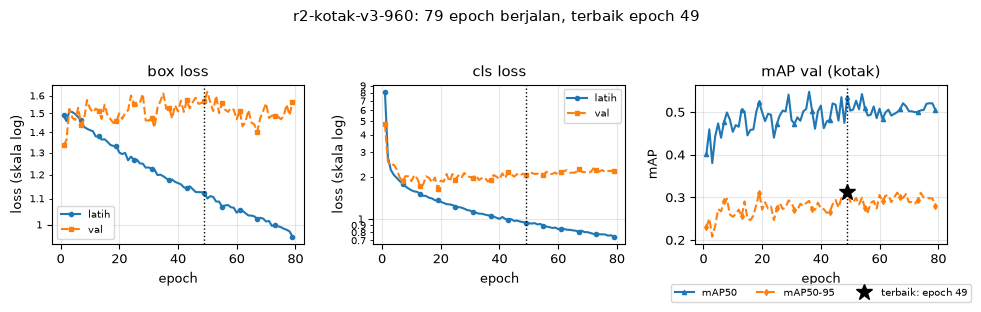

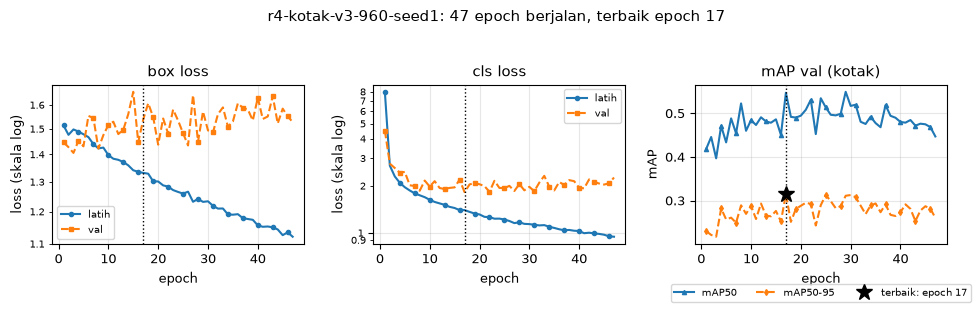

In [14]:
kolom_loss = collections.OrderedDict()
for n in RUN:
    kolom_loss[n] = sorted(c.split("/")[1] for c in RUN[n]["k"] if c.startswith("train/") and c.endswith("_loss"))
pola = collections.Counter(tuple(v) for v in kolom_loss.values())
print("Kolom loss di results.csv:")
for p, c in pola.items():
    print(f"  {c} run: {list(p)}")
print("Ada kolom 'dfl' di salah satu run?", any("dfl" in c for n in RUN for c in RUN[n]["k"]))

def kurva(n):
    R = RUN[n]; k = R["k"]; ep = k["epoch"]; seg = R["tugas"] == "segment"
    panel = [("box", "box_loss"), ("cls", "cls_loss")] + ([("seg", "seg_loss")] if seg else [])
    sfx = "M" if seg else "B"
    jumlah = len(panel) + 1
    kol_n = 2 if seg else jumlah
    baris_n = 2 if seg else 1
    fig, axs = plt.subplots(baris_n, kol_n, figsize=(10, 6.2 if seg else 3.3))
    axs = np.atleast_1d(axs).ravel()
    mk = max(1, len(ep) // 12)
    for ax, (judul, kolom) in zip(axs, panel):
        ax.plot(ep, k["train/" + kolom], "-o", ms=3, markevery=mk, label="latih")
        ax.plot(ep, k["val/" + kolom], "--s", ms=3, markevery=mk, label="val")
        ax.set_yscale("log"); ax.set_title(f"{judul} loss"); ax.set_xlabel("epoch"); ax.set_ylabel("loss (skala log)")
        ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
        ax.yaxis.set_minor_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
        ax.tick_params(axis="y", which="both", labelsize=7)
        ax.axvline(R["best"], color="k", ls=":", lw=1)
        ax.legend(loc="best", fontsize=7)
    ax = axs[len(panel)]
    ax.plot(ep, k[f"metrics/mAP50({sfx})"], "-^", ms=3, markevery=mk, label="mAP50")
    ax.plot(ep, k[f"metrics/mAP50-95({sfx})"], "--d", ms=3, markevery=mk, label="mAP50-95")
    ax.plot(R["best"], k[f"metrics/mAP50-95({sfx})"][R["best"] - 1], "k*", ms=12, label=f"terbaik: epoch {R['best']}")
    ax.axvline(R["best"], color="k", ls=":", lw=1)
    ax.set_title("mAP val" + (" (mask)" if seg else " (kotak)")); ax.set_xlabel("epoch"); ax.set_ylabel("mAP")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=3, fontsize=7)
    for ax in axs[len(panel) + 1:]:
        ax.axis("off")
    fig.suptitle(f"{n}: {R['n_ep']} epoch berjalan, terbaik epoch {R['best']}", y=0.99)
    fig.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()

for n in FINAL[:2]:
    kurva(n)

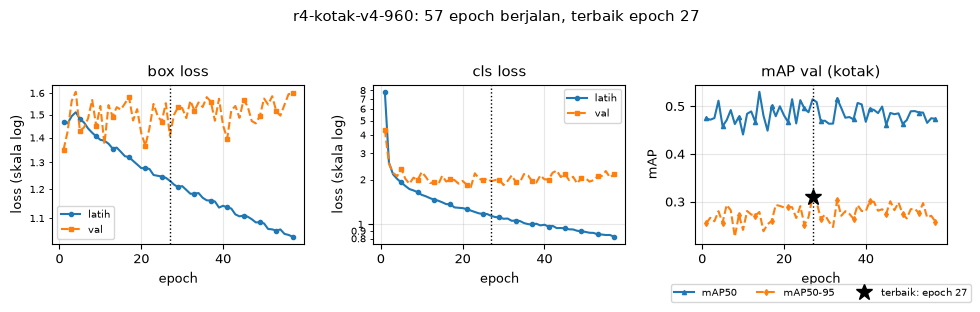

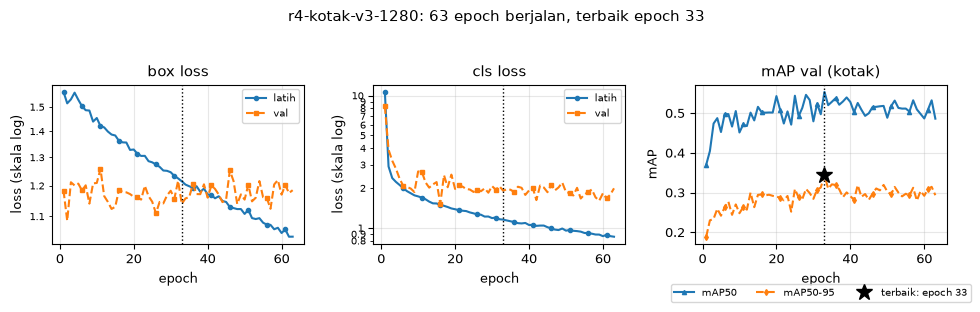

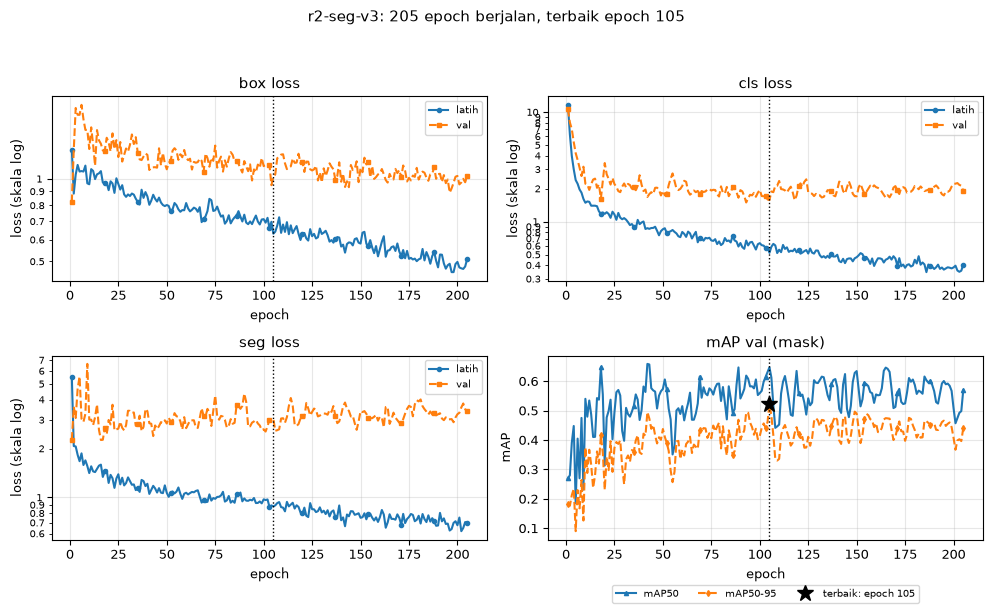

In [15]:
for n in FINAL[2:]:
    kurva(n)

## 5. Pembacaan overfitting dan early stopping
Untuk setiap run: seberapa jauh *loss* val dari *loss* latih pada epoch terbaik, kapan *loss* val paling rendah dibanding kapan mAP paling tinggi,
kapan mAP mulai mendatar (epoch pertama yang mencapai 95% dari mAP50-95 tertinggi), dan bagaimana *early stopping* menghentikan pelatihan.

In [16]:
def sesudah(R):
    k = R["k"]; i = R["best"] - 1
    sfx = "M" if R["tugas"] == "segment" else "B"
    m = k[f"metrics/mAP50-95({sfx})"]
    plateau = int(np.argmax(m >= 0.95 * m.max())) + 1
    return dict(
        gap_box=k["val/box_loss"][i] / k["train/box_loss"][i], gap_cls=k["val/cls_loss"][i] / k["train/cls_loss"][i],
        vmin_box=int(np.argmin(k["val/box_loss"])) + 1, vmin_cls=int(np.argmin(k["val/cls_loss"])) + 1,
        plateau=plateau, n95=int((m >= 0.95 * m.max()).sum()), turun=m[-1] - m[i], setelah=R["n_ep"] - R["best"],
        lr_akhir=k["lr/pg0"][-1] / k["lr/pg0"].max(),
        tr_box_akhir=k["train/box_loss"][-1] / k["train/box_loss"][i], val_box_akhir=k["val/box_loss"][-1] / k["val/box_loss"][i])
S = {n: sesudah(RUN[n]) for n in RUN}
baris = []
for g, n in DAFTAR:
    s = S[n]; R = RUN[n]
    baris.append([nama_tampil(n), R["best"], s["plateau"], f"{s['n95']} dari {R['n_ep']}", s["vmin_box"], s["vmin_cls"], f"{s['gap_box']:.2f}", f"{s['gap_cls']:.2f}",
                  f"{s['tr_box_akhir']:.2f} / {s['val_box_akhir']:.2f}", f"{s['turun']:+.3f}", s["setelah"], R["args"]["patience"], f"{s['lr_akhir']:.2f}"])
tabel(["Run", "Epoch terbaik", "Epoch pertama mAP >= 95% puncak", "Epoch dengan mAP >= 95% puncak", "Epoch val box loss minimum", "Epoch val cls loss minimum",
       "val/latih box loss @terbaik", "val/latih cls loss @terbaik", "box loss akhir / @terbaik (latih / val)", "mAP50-95 akhir - terbaik", "Epoch setelah terbaik", "Patience", "lr akhir / puncak"],
      baris, rata_kanan=list(range(1, 13)))
sama = [n for n in RUN if RUN[n]["berhenti_dini"] and RUN[n]["n_ep"] - RUN[n]["best"] == RUN[n]["args"]["patience"]]

Run,Epoch terbaik,Epoch pertama mAP >= 95% puncak,Epoch dengan mAP >= 95% puncak,Epoch val box loss minimum,Epoch val cls loss minimum,val/latih box loss @terbaik,val/latih cls loss @terbaik,box loss akhir / @terbaik (latih / val),mAP50-95 akhir - terbaik,Epoch setelah terbaik,Patience,lr akhir / puncak
kotak-gabung,39,20,5 dari 69,1,15,1.37,2.05,0.90 / 1.08,-0.061,30,30,0.33
kotak-kampus,60,28,8 dari 160,3,51,1.46,1.90,0.81 / 1.09,-0.036,100,100,0.48
seg-kampus,127,127,7 dari 227,220,156,1.68,2.90,0.70 / 0.85,-0.082,100,100,0.26
r2-kotak-v2bersih,19,19,3 dari 49,1,19,1.15,1.28,0.87 / 1.00,-0.042,30,30,0.54
r2-kotak-v3,19,5,13 dari 49,1,19,1.11,1.25,0.87 / 1.05,-0.034,30,30,0.54
★ r2-kotak-v3-960,49,19,18 dari 79,1,19,1.40,2.20,0.85 / 1.00,-0.032,30,30,0.23
★ r2-seg-v3,105,105,2 dari 205,1,93,1.61,3.03,0.81 / 1.01,-0.083,100,100,0.33
r3-kotak-v3-960-s,15,11,8 dari 45,1,33,0.92,1.46,0.78 / 1.02,-0.020,30,30,0.58
★ r4-kotak-v3-1280,33,33,1 dari 63,2,16,0.94,1.65,0.85 / 1.04,-0.051,30,30,0.39
★ r4-kotak-v3-960-seed1,17,17,5 dari 47,3,17,1.15,1.30,0.84 / 0.99,-0.055,30,30,0.56


In [17]:
fin = list(FINAL)
fin_k = [n for n in fin if RUN[n]["tugas"] == "detect"]
fin_s = [n for n in fin if RUN[n]["tugas"] == "segment"]
rng = lambda xs, f="{}": (f.format(min(xs)) if min(xs) == max(xs) else f.format(min(xs)) + "-" + f.format(max(xs)))
lat_turun = [n for n in fin if S[n]["tr_box_akhir"] < 1]
val_naik = [n for n in fin if S[n]["val_box_akhir"] > 1]
sama_plateau = [n for n in fin if S[n]["plateau"] == RUN[n]["best"]]
cls_awal = [n for n in fin if S[n]["vmin_cls"] <= RUN[n]["best"]]
display(Markdown(
    f"**Bacaan.** (1) *Early stopping* bekerja sesuai aturannya: {len(sama)} dari {len(RUN)} run berhenti tepat `patience` epoch setelah epoch terbaik "
    f"(patience {', '.join(sorted(set(str(RUN[n]['args']['patience']) for n in sama)))}), dan {sum(1 for n in RUN if not RUN[n]['berhenti_dini'])} run mencapai epoch maksimum. "
    f"(2) Epoch terbaik jatuh di tengah, bukan di akhir: model kotak final di epoch {rng([RUN[n]['best'] for n in fin_k])} dari {rng([RUN[n]['n_ep'] for n in fin_k])} epoch berjalan, "
    f"model segmentasi final di epoch {rng([RUN[n]['best'] for n in fin_s])} dari {rng([RUN[n]['n_ep'] for n in fin_s])}. "
    f"(3) mAP val **sangat berfluktuasi** antar epoch (lihat kurva): pada model final hanya {rng([S[n]['n95'] for n in fin])} epoch yang mencapai 95% dari puncak mAP50-95, "
    f"dan epoch pertama yang mencapainya sama dengan epoch terbaik pada {len(sama_plateau)} dari {len(fin)} model. Jadi puncaknya runcing, bukan dataran, dan sebagian dari 'epoch terbaik' kemungkinan keberuntungan pada val yang kecil. "
    f"(4) *Loss* latih terus turun setelah epoch terbaik pada {len(lat_turun)} dari {len(fin)} model final, sedangkan *loss* val box lebih tinggi daripada pada epoch terbaik di {len(val_naik)} model dan "
    f"*loss* val cls paling rendah di epoch {', '.join(str(S[n]['vmin_cls']) for n in fin)} (epoch terbaik mAP: {', '.join(str(RUN[n]['best']) for n in fin)}); pola ini konsisten dengan *overfitting* setelah epoch terbaik, "
    f"tetapi angkanya tidak cukup untuk menilai seberapa parah. *Loss* val box paling rendah justru di epoch {', '.join(str(S[n]['vmin_box']) for n in fin)}: ukuran ini nyaris tidak berguna sebagai kriteria pemilihan epoch, "
    f"jadi memilih lewat mAP (cara Ultralytics) masuk akal, tetapi tetap bergantung pada val yang kecil. "
    f"(5) Rasio *loss* val terhadap latih pada epoch terbaik berkisar {min(S[n]['gap_box'] for n in fin):.2f}-{max(S[n]['gap_box'] for n in fin):.2f} (box) dan {min(S[n]['gap_cls'] for n in fin):.2f}-{max(S[n]['gap_cls'] for n in fin):.2f} (cls); "
    "angka ini tidak murni karena augmentasi hanya ada di sisi latih. "
    f"(6) Jadwal *learning rate* dirancang untuk epoch maksimum, sehingga saat berhenti dini lr masih {min(S[n]['lr_akhir'] for n in fin):.2f}-{max(S[n]['lr_akhir'] for n in fin):.2f} dari puncaknya: "
    "model tidak pernah mengalami bagian jadwal dengan lr yang sangat kecil."))

**Bacaan.** (1) *Early stopping* bekerja sesuai aturannya: 12 dari 12 run berhenti tepat `patience` epoch setelah epoch terbaik (patience 100, 30), dan 0 run mencapai epoch maksimum. (2) Epoch terbaik jatuh di tengah, bukan di akhir: model kotak final di epoch 17-49 dari 47-79 epoch berjalan, model segmentasi final di epoch 105 dari 205. (3) mAP val **sangat berfluktuasi** antar epoch (lihat kurva): pada model final hanya 1-18 epoch yang mencapai 95% dari puncak mAP50-95, dan epoch pertama yang mencapainya sama dengan epoch terbaik pada 4 dari 5 model. Jadi puncaknya runcing, bukan dataran, dan sebagian dari 'epoch terbaik' kemungkinan keberuntungan pada val yang kecil. (4) *Loss* latih terus turun setelah epoch terbaik pada 5 dari 5 model final, sedangkan *loss* val box lebih tinggi daripada pada epoch terbaik di 3 model dan *loss* val cls paling rendah di epoch 19, 17, 22, 16, 93 (epoch terbaik mAP: 49, 17, 27, 33, 105); pola ini konsisten dengan *overfitting* setelah epoch terbaik, tetapi angkanya tidak cukup untuk menilai seberapa parah. *Loss* val box paling rendah justru di epoch 1, 3, 1, 2, 1: ukuran ini nyaris tidak berguna sebagai kriteria pemilihan epoch, jadi memilih lewat mAP (cara Ultralytics) masuk akal, tetapi tetap bergantung pada val yang kecil. (5) Rasio *loss* val terhadap latih pada epoch terbaik berkisar 0.94-1.61 (box) dan 1.30-3.03 (cls); angka ini tidak murni karena augmentasi hanya ada di sisi latih. (6) Jadwal *learning rate* dirancang untuk epoch maksimum, sehingga saat berhenti dini lr masih 0.23-0.56 dari puncaknya: model tidak pernah mengalami bagian jadwal dengan lr yang sangat kecil.

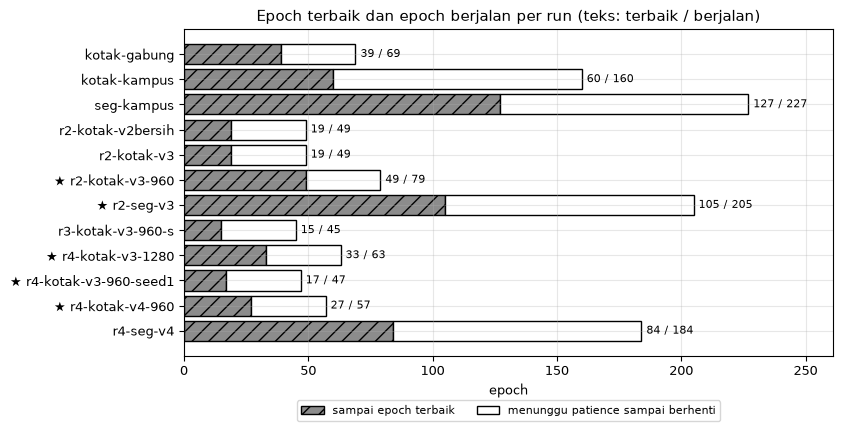

In [18]:
# satu ide: berapa epoch sampai terbaik dan berapa epoch "sia-sia" menunggu patience
fig, ax = plt.subplots(figsize=(8.5, 4.4))
urut = [n for g, n in DAFTAR][::-1]
ytik = np.arange(len(urut))
ax.barh(ytik, [RUN[n]["best"] for n in urut], color="0.55", edgecolor="k", hatch="//", label="sampai epoch terbaik")
ax.barh(ytik, [RUN[n]["n_ep"] - RUN[n]["best"] for n in urut], left=[RUN[n]["best"] for n in urut], color="white", edgecolor="k", label="menunggu patience sampai berhenti")
for y, n in zip(ytik, urut):
    ax.text(RUN[n]["n_ep"] + 2, y, f"{RUN[n]['best']} / {RUN[n]['n_ep']}", va="center", fontsize=8)
ax.set_yticks(ytik); ax.set_yticklabels([nama_tampil(n) for n in urut])
ax.set_xlabel("epoch"); ax.set_title("Epoch terbaik dan epoch berjalan per run (teks: terbaik / berjalan)")
ax.set_xlim(0, max(RUN[n]["n_ep"] for n in RUN) * 1.15)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, fontsize=8)
fig.tight_layout(); plt.show()

## 6. Contoh keluaran Ultralytics: `results.png`
Gambar ringkasan bawaan Ultralytics untuk satu model final (`r2-kotak-v3-960`), sebagai pembanding grafik buatan sendiri di atas.
Gambar ini hanya berisi kurva, tidak ada foto.

Ukuran asli: (2400, 1200) -> ditampilkan lebar <= 1000 px


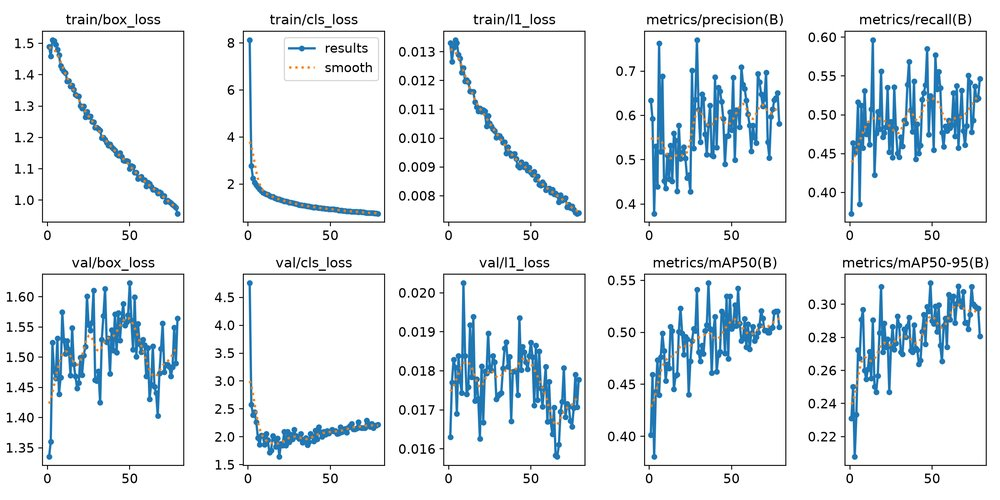

In [19]:
p = RUNS / "ronde2" / "r2-kotak-v3-960" / "results.png"
cek_putih(p)
im = Image.open(p)
print("Ukuran asli:", im.size, "-> ditampilkan lebar <= 1000 px")
if im.size[0] > 1000:
    im = im.resize((1000, int(im.size[1] * 1000 / im.size[0])), Image.LANCZOS)
tampil_jpeg(im, mutu=85)

## 7. Keterbatasan
Angka di bawah dihitung dari berkas yang sama dengan bagian sebelumnya.

In [20]:
val_n = {RUN[n]["meta"]["jumlah_gambar"]["val"] for n in RUN}
adaresume = [n for n in RUN if len(RUN[n]["meta"]["segmen"]) > 1 or any(s["resume"] for s in RUN[n]["meta"]["segmen"])]
satu_seed = [n for n in RUN if RUN[n]["args"]["seed"] == 0]
pat = collections.Counter(RUN[n]["args"]["patience"] for n in RUN)
mx_ep = max(RUN[n]["n_ep"] for n in RUN)
baris = [
    ["Ukuran val saat pelatihan", f"{', '.join(str(v) for v in sorted(val_n))} gambar (sama untuk semua run); sebaran lokasi val: lihat Notebook 01"],
    ["Run dengan seed 0 (satu kali pelatihan per konfigurasi)", f"{len(satu_seed)} dari {len(RUN)} run; seed lain hanya {', '.join(seed_lain)}"],
    ["Pemilihan epoch terbaik", f"pada val yang sama dengan yang dilaporkan di tabel (val v2, atau v1 untuk baseline); {len(RUN)} run, hingga {mx_ep} epoch dibandingkan per run"],
    ["Validasi silang (k-fold)", "tidak dilakukan; satu pembagian train / val / test per lokasi"],
    ["Run yang di-resume", f"{len(adaresume)} (tidak ada epoch yang terhitung dua kali)" if not adaresume else ", ".join(adaresume)],
    ["Patience berbeda antar run", ", ".join(f"{p_} ({c} run)" for p_, c in sorted(pat.items()))],
    ["Folder smoke (uji batch/worker) tidak dihitung", f"{n_smoke} folder"],
    ["Ablasi tidak murni", "pada beberapa pasangan run lebih dari satu hal berubah sekaligus (data, imgsz, batch, jumlah langkah optimizer)"],
    ["close_mosaic tercapai", f"{len(ditutup)} dari {len(RUN)} run"],
]
tabel(["Keterbatasan", "Angka (dihitung)"], baris)

Keterbatasan,Angka (dihitung)
Ukuran val saat pelatihan,54 gambar (sama untuk semua run); sebaran lokasi val: lihat Notebook 01
Run dengan seed 0 (satu kali pelatihan per konfigurasi),11 dari 12 run; seed lain hanya r4-kotak-v3-960-seed1
Pemilihan epoch terbaik,"pada val yang sama dengan yang dilaporkan di tabel (val v2, atau v1 untuk baseline); 12 run, hingga 227 epoch dibandingkan per run"
Validasi silang (k-fold),tidak dilakukan; satu pembagian train / val / test per lokasi
Run yang di-resume,0 (tidak ada epoch yang terhitung dua kali)
Patience berbeda antar run,"30 (8 run), 100 (4 run)"
Folder smoke (uji batch/worker) tidak dihitung,19 folder
Ablasi tidak murni,"pada beberapa pasangan run lebih dari satu hal berubah sekaligus (data, imgsz, batch, jumlah langkah optimizer)"
close_mosaic tercapai,0 dari 12 run


- **Val kecil dan dipakai berulang.** Val dipakai untuk memilih epoch terbaik (`best.pt`), untuk *early stopping*, dan untuk memutuskan ronde 2-4, lalu
  dilaporkan sebagai hasil. Semua angka val di notebook ini cenderung optimistis. Selisih antar run sekecil derau antar seed tidak berarti kemajuan.
- **Satu seed untuk hampir semua run.** Hanya satu pasangan (dua seed pada konfigurasi yang sama) yang menunjukkan besar derau; tidak ada interval kepercayaan.
- **Tidak ada validasi silang (k-fold).** Dengan val dan data kampus berlabel sekecil ini (angkanya di Notebook 01), pembagian lain bisa memberi urutan model yang berbeda.
- **Val baseline berbeda dari val ronde 2 ke atas.** Baseline divalidasi pada label val sebelum audit; metrik `results.csv` tidak sebanding antar kelompok itu. Perbandingan yang adil
  ada pada evaluasi ulang di val v2 (`docs/hasil-ronde2.md`).
- **Perbandingan tidak murni.** Imgsz, batch, patience, jumlah langkah optimizer, dan dataset berubah bersamaan pada beberapa run; efek satu faktor tidak terpisah.
- **Loss latih dan val tidak setara** karena augmentasi hanya di sisi latih; *overfitting* di sini dibaca dari pola, bukan dari satu angka.
- **Lingkungan satu laptop.** Waktu latih dan VRAM hanya berlaku untuk RTX 4060 Laptop 8 GB; kecepatan HP tidak diukur di sini.
- **Ensemble dipilih dengan val yang sama dan syarat kecepatan bergantung kondisi mesin** (lihat 3.4).

## 8. Pemeriksaan konsistensi antar sumber
Tabel ini membandingkan epoch berjalan, epoch terbaik, dan waktu dari beberapa sumber: `results.csv` (dihitung ulang), `meta.json`, `train.log`, dan dokumen hasil
(`docs/hasil-baseline.md`, `docs/hasil-ronde2.md`, `LOG.md` untuk ronde 3). Tidak ada angka yang disesuaikan; selisih ditandai apa adanya. Waktu dibandingkan dengan toleransi 3%
karena `train.log` membulatkan ke 0,001 jam dan mengukur sedikit berbeda dari `meta.json`.

In [21]:
dok_b = {r[0].replace("`", ""): r for r in tabel_md(tx_b, "| Run | Epoch berjalan | Best epoch |")}
dok_2 = {r[0].replace("`", ""): r for r in tabel_md(tx_2, "| Run | Data train | imgsz |")}
m_r3 = re.search(r"early stopping di epoch (\d+) \(terbaik epoch (\d+)", entri("R3-4"))
dok = {}                                                 # nama -> (epoch berjalan, terbaik, menit)
for n, r in dok_b.items():
    dok[n] = (int(r[1]), int(r[2]), None, float(re.match(r"([\d.]+) s", r[4]).group(1).replace(".", "")))
for n, r in dok_2.items():
    dok[n] = (int(r[4]), int(r[5]), angka_id(r[6].replace("mnt", "")), None)
dok["r3-kotak-v3-960-s"] = (int(m_r3.group(1)), int(m_r3.group(2)), None, None)
baris, beda = [], []
for g, n in DAFTAR:
    R = RUN[n]; m = R["meta"]
    ep_ok = len({R["n_ep"], m["epoch_terakhir"], R["ep_log"]}) == 1
    best_ok = R["best"] == R["best_log"]
    det = m["total_detik_latih"]
    t_log = abs(det / 3600 - R["jam_log"]) / R["jam_log"] <= 0.03
    d = dok.get(n)
    if d:
        d_ep = d[0] == R["n_ep"]; d_best = d[1] == R["best"]
        d_t = (round(det / 60, 1) == d[2]) if d[2] is not None else (round(det) == d[3] if d[3] is not None else None)
        dtxt = f"{d[0]} / {d[1]}"
    else:
        d_ep = d_best = d_t = None; dtxt = "-"
    ok = ep_ok and best_ok and t_log and all(x in (True, None) for x in (d_ep, d_best, d_t))
    if not ok:
        beda.append(n)
    baris.append([nama_tampil(n), f"{R['n_ep']} / {m['epoch_terakhir']} / {R['ep_log']}", f"{R['best']} / {R['best_log']}", f"{det / 3600:.3f} / {R['jam_log']:.3f}", dtxt,
                  "OK" if ok else "BEDA"])
tabel(["Run", "Epoch berjalan: csv / meta / log", "Epoch terbaik: dihitung csv / log", "Jam: meta / log", "Dokumen: berjalan / terbaik", "Status"], baris)
print("Run dengan selisih antar sumber:", beda or "tidak ada")

Run,Epoch berjalan: csv / meta / log,Epoch terbaik: dihitung csv / log,Jam: meta / log,Dokumen: berjalan / terbaik,Status
kotak-gabung,69 / 69 / 69,39 / 39,0.796 / 0.792,69 / 39,OK
kotak-kampus,160 / 160 / 160,60 / 60,0.141 / 0.138,160 / 60,OK
seg-kampus,227 / 227 / 227,127 / 127,0.391 / 0.387,227 / 127,OK
r2-kotak-v2bersih,49 / 49 / 49,19 / 19,0.375 / 0.371,49 / 19,OK
r2-kotak-v3,49 / 49 / 49,19 / 19,0.392 / 0.389,49 / 19,OK
★ r2-kotak-v3-960,79 / 79 / 79,49 / 49,1.370 / 1.367,79 / 49,OK
★ r2-seg-v3,205 / 205 / 205,105 / 105,0.265 / 0.262,205 / 105,OK
r3-kotak-v3-960-s,45 / 45 / 45,15 / 15,1.459 / 1.456,45 / 15,OK
★ r4-kotak-v3-1280,63 / 63 / 63,33 / 33,2.224 / 2.221,-,OK
★ r4-kotak-v3-960-seed1,47 / 47 / 47,17 / 17,1.010 / 1.008,-,OK


Run dengan selisih antar sumber: tidak ada


In [22]:
print("Gambar berkas yang ditampilkan di notebook ini:")
for g in GAMBAR_TAMPIL:
    print(" -", g)
print("Grafik lain dibuat oleh matplotlib dari results.csv dan JSON (bukan berkas gambar).")
print()
print("Epoch terbaik / epoch berjalan model final:")
for n in FINAL:
    print(f"  {n}: terbaik {RUN[n]['best']}, berjalan {RUN[n]['n_ep']}")

Gambar berkas yang ditampilkan di notebook ini:
 - runs/ronde2/r2-kotak-v3-960/results.png
Grafik lain dibuat oleh matplotlib dari results.csv dan JSON (bukan berkas gambar).

Epoch terbaik / epoch berjalan model final:
  r2-kotak-v3-960: terbaik 49, berjalan 79
  r4-kotak-v3-960-seed1: terbaik 17, berjalan 47
  r4-kotak-v4-960: terbaik 27, berjalan 57
  r4-kotak-v3-1280: terbaik 33, berjalan 63
  r2-seg-v3: terbaik 105, berjalan 205
